# Level 3: From weak field to Paschen-Back

**Goal.** Follow the levels continuously as $B$ grows from "weak" ($\mu_B B \ll \zeta$) to "strong"
($\mu_B B \gg \zeta$), and see $\mathbf L$ and $\mathbf S$ decouple.

**Physics.** In a strong field the Zeeman term wins and $m_l, m_s$ become good quantum numbers:
$$E \simeq \mu_B B\,(m_l + g_s m_s) + \zeta\, m_l m_s .$$
The crossover field is $B^\ast = \zeta/\mu_B$.

**Numerical subtlety.** `numpy.linalg.eigh` always returns eigenvalues *sorted*. When two physical
levels cross, sorting swaps them and hides the crossing. `solvers.track_levels` follows each level
by matching eigenvectors from one field step to the next.

B* = 24.6 T


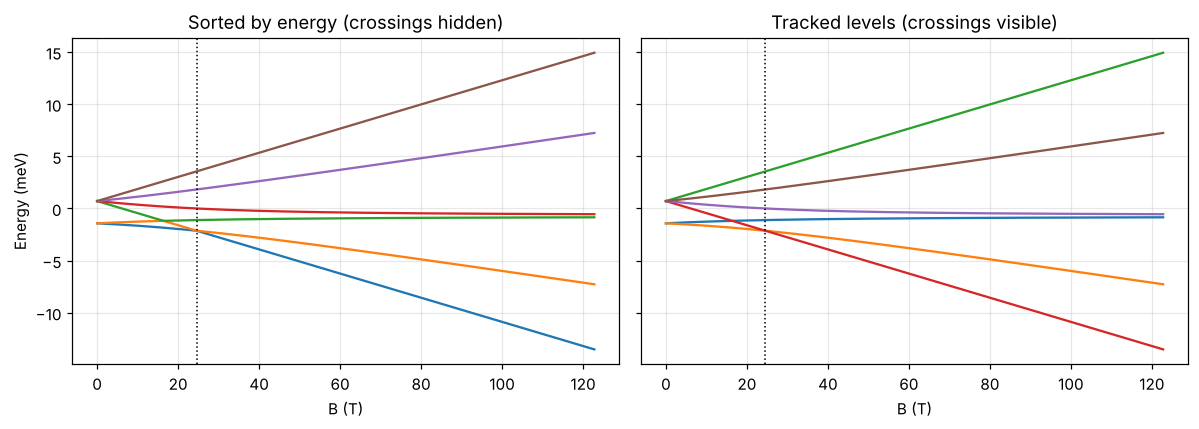

In [1]:
import sys
sys.path.insert(0, '..')          # so `import src...` works from the notebooks folder
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3})
from src.validation import zeta_from_fine_structure
from src.solvers import energy_vs_field, track_levels
from src.constants import MU_B_EV, G_S

zeta = zeta_from_fine_structure(17.196, l=1)
bstar = zeta / MU_B_EV
b = np.linspace(0, 5 * bstar, 400)
print('B* = %.1f T' % bstar)

sorted_e = energy_vs_field(1, b, zeta)
tracked = track_levels(1, b, zeta)

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for k in range(6):
    axes[0].plot(b, sorted_e[:, k] * 1e3)
    axes[1].plot(b, tracked[:, k] * 1e3)
axes[0].set_title('Sorted by energy (crossings hidden)')
axes[1].set_title('Tracked levels (crossings visible)')
for a in axes:
    a.set_xlabel('B (T)'); a.axvline(bstar, color='k', ls=':', lw=1)
axes[0].set_ylabel('Energy (meV)')
plt.tight_layout(); plt.show()

The dotted line marks $B^\ast$. Levels with different $m_j = m_l + m_s$ really do cross (right panel).
Levels with the *same* $m_j$ repel each other and never cross. Sorting merges both pictures into one.

## Compare with the Paschen-Back formula

Overlay the strong-field prediction on the exact curves:

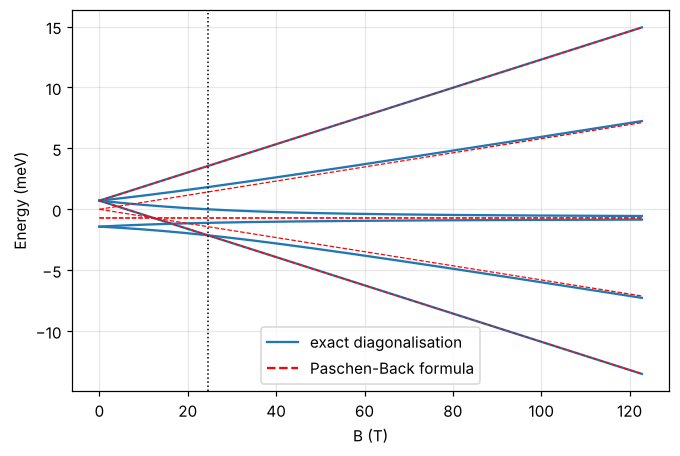

In [2]:
fig, ax = plt.subplots(figsize=(7, 4.5))
for k in range(6):
    ax.plot(b, tracked[:, k] * 1e3, color='tab:blue', lw=1.5)
for ml in (1, 0, -1):
    for ms in (0.5, -0.5):
        pb = MU_B_EV * b * (ml + G_S * ms) + zeta * ml * ms
        ax.plot(b, pb * 1e3, 'r--', lw=0.8)
ax.plot([], [], color='tab:blue', label='exact diagonalisation')
ax.plot([], [], 'r--', label='Paschen-Back formula')
ax.axvline(bstar, color='k', ls=':', lw=1)
ax.set_xlabel('B (T)'); ax.set_ylabel('Energy (meV)'); ax.legend()
plt.show()

In [3]:
# Slopes at a very large field (100 B*) versus the strong-field prediction (m_l + g_s m_s)
b_hi = np.array([100 * bstar, 101 * bstar])
e_hi = energy_vs_field(1, b_hi, zeta)
slopes = np.sort((e_hi[1] - e_hi[0]) / (b_hi[1] - b_hi[0]) / MU_B_EV)
pred = np.sort([ml + G_S * ms for ml in (1, 0, -1) for ms in (0.5, -0.5)])
print('%10s %10s' % ('slope/mu_B', 'ml+gs*ms'))
for s_, p_ in zip(slopes, pred):
    print('%10.4f %10.4f' % (s_, p_))

slope/mu_B   ml+gs*ms
   -2.0012    -2.0012
   -1.0011    -1.0012
   -0.0011    -0.0012
    0.0011     0.0012
    1.0011     1.0012
    2.0012     2.0012


The agreement improves as $B$ grows: at $5B^\ast$ the slopes are still a couple of percent off because
the spin-orbit term keeps mixing states of equal $m_j$, but at $100B^\ast$ they match the formula.

**Take-away.** Below $B^\ast$ the levels are grouped by $j$ (Level 2); far above it they are grouped by
$m_l + g_s m_s$ and the red dashed lines match. The two stretched states ($m_l = \pm1$, $m_s = \pm\tfrac12$)
are exact at every field, which the unit tests check. The animation `docs/figures/p_orbital_split.gif`
shows the same transition as a movie.